# Deliverable 2 – Python Data Analysis Notebook (Instructor Example)

**Dataset:** City 311 Service Requests (synthetic, 2023 – Sept 2025) &nbsp;|&nbsp; **File:** `service_requests_raw.csv`

> **About this example.** This notebook shows the *level of work and the structure* expected for Deliverable 2. The data is synthetic (generated for teaching) but was built to look like a real city 311 export — including the messy parts: duplicate rows, inconsistent spelling, placeholder values, impossible dates, missing values, and outliers. **Your project will use your own dataset**; copy this structure, not these findings.

### Business context
A city operations team wants a dashboard to answer three questions from the proposal:

1. **Q1 – Speed:** Which request categories take the longest to resolve, and how much does priority level change that?
2. **Q2 – Demand:** How has request volume changed over time, and which categories are seasonal?
3. **Q3 – Experience:** Do slower resolutions lead to lower resident satisfaction, and does that differ by channel or district?

### How this notebook maps to the Deliverable 2 requirements

| Requirement | Where it is in this notebook |
|---|---|
| **A.** Load and understand the data | Section 1 |
| **B.** Prepare and explore (clean, groupby, calculated columns, three questions) | Sections 2 – 4 |
| **C.** Three+ labeled charts, interpretation, pick the strongest three | Sections 5 – 6 |
| **D.** Reduced dashboard CSV | Section 7 |
| Markdown explaining the analysis | Throughout |

### Contents
1. Load and understand the data
2. Clean and prepare the data
3. Descriptive statistics, distributions, and missingness
4. Explore categories and investigate the three questions
5. Visualizations with filters (the dashboard charts)
6. Which charts go in the dashboard?
7. Save the dashboard dataset
8. Dashboard hand-off specification (for the AI-assisted Streamlit build)

---
## 1. Load and understand the data

### 1.1 Import libraries
We use **pandas** for data work and **matplotlib / seaborn** for charts. Every library imported here must also go in your `requirements.txt` if the dashboard uses it.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RAW_FILE = "service_requests_raw.csv"
DASHBOARD_FILE = "dashboard_data.csv"

### 1.2 Load the data into a DataFrame
We keep an untouched copy (`df_raw`) so we can always compare against the original and prove what our cleaning changed.

In [2]:
df_raw = pd.read_csv(RAW_FILE)
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
df_raw.head(8)

Rows: 6,065   Columns: 10


,request_id,created_date,closed_date,category,district,channel,priority,status,cost_estimate,satisfaction_score
0,SR-104778,2024-08-26 18:34,2024-09-02 23:22,Street Light Outage,University,Phone,High,Closed,760.28,4.00
1,SR-100027,2025-02-13 22:04,2025-02-18 07:40,Missed Trash Pickup,West End,Mobile App,Low,Closed,66.17,5.00
2,SR-104181,2024-05-10 05:44,2024-05-19 15:20,Graffiti Removal,East Side,Mobile App,Medium,Closed,194.30,NaN
3,SR-100996,2024-10-11 17:20,2024-10-25 14:56,Tree Down,University,Walk-in,Low,Closed,595.90,3.00
4,SR-103929,2025-03-14 04:23,2025-03-28 04:23,Street Light Outage,University,Phone,Low,Closed,NaN,4.00
5,SR-103452,2023-05-21 07:41,2023-05-27 05:17,Tree Down,West End,Web Portal,High,Closed,219.18,4.00
6,SR-101156,2024-09-11 08:07,2024-09-16 20:07,Pothole Repair,North End,Web Portal,High,Closed,501.20,NaN
7,SR-100776,2025-01-11 14:01,2025-01-26 11:37,Pothole Repair,East Side,Web Portal,Medium,Closed,702.78,5.00


### 1.3 Inspect structure: columns, data types, record counts
`info()` shows each column's type and non-null count. Watch for **dates stored as text (`object`)** and for columns whose non-null count is lower than the row count.

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6065 entries, 0 to 6064
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   request_id          6065 non-null   str    
 1   created_date        6056 non-null   str    
 2   closed_date         6058 non-null   str    
 3   category            6065 non-null   str    
 4   district            6004 non-null   str    
 5   channel             5995 non-null   str    
 6   priority            6014 non-null   str    
 7   status              6065 non-null   str    
 8   cost_estimate       5772 non-null   float64
 9   satisfaction_score  3878 non-null   float64
dtypes: float64(2), str(8)
memory usage: 474.0 KB


### 1.4 Data dictionary (what each column means)

| Column | Meaning | Expected type |
|---|---|---|
| `request_id` | Unique ticket number (`SR-######`) | text (ID) |
| `created_date` | When the resident submitted the request | datetime |
| `closed_date` | When the city closed the request (blank if still open) | datetime |
| `category` | Type of problem reported | categorical |
| `district` | City district where the problem is located | categorical |
| `channel` | How the request was submitted | categorical |
| `priority` | Priority assigned by the city (Low / Medium / High) | ordered categorical |
| `status` | Open, Closed, or Cancelled | categorical |
| `cost_estimate` | Estimated repair cost in dollars | numeric |
| `satisfaction_score` | Resident survey score, 1 (poor) – 5 (excellent); only collected after closure | numeric (ordinal) |

### 1.5 Data-quality checks
Before cleaning, **diagnose** problems. We check missing values, duplicates, category spelling, and impossible values.

In [4]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(1),
})
missing.sort_values("missing_pct", ascending=False)

,missing_count,missing_pct
satisfaction_score,2187,36.10
cost_estimate,293,4.80
channel,70,1.20
district,61,1.00
priority,51,0.80
created_date,9,0.10
closed_date,7,0.10
request_id,0,0.00
category,0,0.00
status,0,0.00


In [5]:
print("Exact duplicate rows:          ", df_raw.duplicated().sum())
print("Duplicate request_id values:   ", df_raw["request_id"].duplicated().sum())
print()
for col in ["category", "district", "channel", "priority", "status"]:
    print(f"--- {col} ---")
    print(df_raw[col].value_counts(dropna=False).to_string())
    print()

Exact duplicate rows:           65
Duplicate request_id values:    65

--- category ---
category
Pothole Repair           1067
Missed Trash Pickup       955
Noise Complaint           869
Street Light Outage       842
Illegal Dumping           681
Graffiti Removal          474
Water Leak                466
Tree Down                 443
POTHOLE REPAIR             33
NOISE COMPLAINT            27
 Pothole Repair            24
MISSED TRASH PICKUP        23
STREET LIGHT OUTAGE        21
 Missed Trash Pickup       18
 Street Light Outage       17
ILLEGAL DUMPING            16
 Illegal Dumping           15
 Tree Down                 15
 Noise Complaint           13
GRAFFITI REMOVAL           10
TREE DOWN                   9
 Graffiti Removal           8
 Water Leak                 8
WATER LEAK                  8
 MISSED TRASH PICKUP        1
 POTHOLE REPAIR             1
 NOISE COMPLAINT            1

--- district ---
district
University    1179
South Park    1047
North End      975
East Side

In [6]:
# Date logic: a request cannot be closed before it was created
created = pd.to_datetime(df_raw["created_date"], errors="coerce")
closed = pd.to_datetime(df_raw["closed_date"], errors="coerce")
print("Rows where closed_date is BEFORE created_date:", (closed < created).sum())
print("Date range of created_date:", created.min(), "->", created.max())

Rows where closed_date is BEFORE created_date: 15
Date range of created_date: 2023-01-01 10:09:00 -> 2025-09-30 18:30:00


### 1.6 What we found (data-quality log)

| # | Issue | Evidence | Planned fix |
|---|---|---|---|
| 1 | **Duplicate rows** | ~65 exact duplicate rows (repeated `request_id`) | Drop exact duplicates |
| 2 | **Inconsistent text in `category`** | `POTHOLE REPAIR`, ` Pothole Repair ` (extra spaces) alongside `Pothole Repair` | Strip whitespace and standardize case |
| 3 | **Inconsistent `district` values** | lowercase variants and abbreviations (`S. Park`, `N End`) | Standardize to official names |
| 4 | **Placeholder `"N/A"` in `channel`** | Text `N/A` is *not* recognized as missing by pandas | Convert to real missing, then label `Unknown` |
| 5 | **Missing `priority`, `district`, `created_date`** | Small counts of blanks | `Unknown` label for categories; drop rows with no created date (can't be placed in time) |
| 6 | **Dates stored as text** | `created_date` / `closed_date` are `object` dtype | Convert with `pd.to_datetime` |
| 7 | **Impossible dates** | `closed_date` earlier than `created_date` | Set `closed_date` to missing and flag |
| 8 | **Cost outliers** | A few `cost_estimate` values ~25× the typical for their category | Flag, don't delete |
| 9 | **Structural missingness** | `satisfaction_score` blank for most rows | Investigate *why* before deciding (Section 3.3) |

---
## 2. Clean and prepare the data

**Rule of thumb:** work on a *copy*, change one issue at a time, and **record how many rows each step affects**. That log is evidence your cleaning was deliberate, not accidental.

In [7]:
df = df_raw.copy()
cleaning_log = []

def log(step, before, after):
    cleaning_log.append({"step": step, "rows_before": before, "rows_after": after, "rows_removed": before - after})

# 1. Remove exact duplicate rows
n = len(df)
df = df.drop_duplicates()
log("Drop exact duplicates", n, len(df))

# 2. Standardize text columns: strip spaces, then consistent capitalization
for col in ["category", "district", "channel", "priority", "status"]:
    df[col] = df[col].str.strip().str.title()

# 3. Fix district abbreviations
df["district"] = df["district"].replace({"S. Park": "South Park", "N End": "North End"})

# 4. Turn the "N/A" placeholder into a real missing value
df["channel"] = df["channel"].replace({"N/A": np.nan})

# 5. Convert date text -> datetime
df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
df["closed_date"] = pd.to_datetime(df["closed_date"], errors="coerce")

# 6. Drop rows with no created date (cannot be placed on a timeline)
n = len(df)
df = df.dropna(subset=["created_date"])
log("Drop rows with missing created_date", n, len(df))

# 7. Impossible dates: closed before created -> blank out and flag
bad_dates = df["closed_date"] < df["created_date"]
df["date_error_flag"] = bad_dates
df.loc[bad_dates, "closed_date"] = pd.NaT
print(f"Fixed {bad_dates.sum()} rows where closed_date was before created_date")

# 8. Missing categorical values -> explicit 'Unknown' (keeps the rows, keeps them visible)
for col in ["district", "channel", "priority"]:
    df[col] = df[col].fillna("Unknown")

# 9. Make priority an ordered category so charts sort Low -> Medium -> High
priority_order = ["Low", "Medium", "High", "Unknown"]
df["priority"] = pd.Categorical(df["priority"], categories=priority_order, ordered=True)

pd.DataFrame(cleaning_log)

Fixed 15 rows where closed_date was before created_date


,step,rows_before,rows_after,rows_removed
0,Drop exact duplicates,6065,6000,65
1,Drop rows with missing created_date,6000,5992,8


### 2.1 Verify the fixes
Re-run the same checks from Section 1. **Never assume a cleaning step worked — prove it.**

In [8]:
for col in ["category", "district", "channel", "priority", "status"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string())
    print()
print("Duplicate request_ids remaining:", df["request_id"].duplicated().sum())

--- category ---
category
Pothole Repair         1110
Missed Trash Pickup     989
Noise Complaint         902
Street Light Outage     866
Illegal Dumping         702
Graffiti Removal        486
Water Leak              475
Tree Down               462

--- district ---
district
University    1182
South Park    1060
North End      989
East Side      946
West End       918
Downtown       837
Unknown         60

--- channel ---
channel
Mobile App    2254
Phone         1570
Web Portal    1537
Walk-In        561
Unknown         70

--- priority ---
priority
Low        2621
Medium     2313
High       1008
Unknown      50

--- status ---
status
Closed       5874
Cancelled     112
Open            6

Duplicate request_ids remaining: 0


### 2.2 Create calculated columns
These new columns drive the analysis **and** the dashboard filters. Document *why* each exists.

| New column | Why |
|---|---|
| `resolution_days` | Core speed metric for Q1 and Q3 |
| `year`, `month`, `year_month` | Time grouping and a year filter for Q2 |
| `sla_days`, `is_late` | Policy targets by priority (High 3 days, Medium 7, Low 14) so we can report "% late" |
| `cost_is_outlier` | Flags suspicious cost values instead of silently deleting them |

In [9]:
# Resolution time in days (NaN for open/cancelled requests that have no closed_date)
df["resolution_days"] = (df["closed_date"] - df["created_date"]).dt.total_seconds() / 86400

# Time features
df["year"] = df["created_date"].dt.year
df["month"] = df["created_date"].dt.month
df["year_month"] = df["created_date"].dt.to_period("M").dt.to_timestamp()

# Service-level target by priority, and whether each closed request missed it
sla_map = {"High": 3, "Medium": 7, "Low": 14}
df["sla_days"] = df["priority"].astype(str).map(sla_map)
df["is_late"] = np.where(
    df["resolution_days"].notna() & df["sla_days"].notna(),
    df["resolution_days"] > df["sla_days"],
    np.nan,
)

# Flag cost outliers: more than 5x the median cost of their own category
cat_median_cost = df.groupby("category")["cost_estimate"].transform("median")
df["cost_is_outlier"] = df["cost_estimate"] > 5 * cat_median_cost.replace(0, np.nan)

df[["request_id", "category", "priority", "created_date", "closed_date",
    "resolution_days", "sla_days", "is_late", "cost_is_outlier"]].head(8)

,request_id,category,priority,created_date,closed_date,resolution_days,sla_days,is_late,cost_is_outlier
0,SR-104778,Street Light Outage,High,2024-08-26 18:34:00,2024-09-02 23:22:00,7.20,3.00,1.00,False
1,SR-100027,Missed Trash Pickup,Low,2025-02-13 22:04:00,2025-02-18 07:40:00,4.40,14.00,0.00,False
2,SR-104181,Graffiti Removal,Medium,2024-05-10 05:44:00,2024-05-19 15:20:00,9.40,7.00,1.00,False
3,SR-100996,Tree Down,Low,2024-10-11 17:20:00,2024-10-25 14:56:00,13.90,14.00,0.00,False
4,SR-103929,Street Light Outage,Low,2025-03-14 04:23:00,2025-03-28 04:23:00,14.00,14.00,0.00,False
5,SR-103452,Tree Down,High,2023-05-21 07:41:00,2023-05-27 05:17:00,5.90,3.00,1.00,False
6,SR-101156,Pothole Repair,High,2024-09-11 08:07:00,2024-09-16 20:07:00,5.50,3.00,1.00,False
7,SR-100776,Pothole Repair,Medium,2025-01-11 14:01:00,2025-01-26 11:37:00,14.90,7.00,1.00,False


In [10]:
print(f"Clean dataset: {len(df):,} rows (raw had {len(df_raw):,})")
print("Cost outliers flagged:", int(df["cost_is_outlier"].sum()))

Clean dataset: 5,992 rows (raw had 6,065)
Cost outliers flagged: 12


---
## 3. Descriptive statistics, distributions, and missingness

### 3.1 Descriptive statistics
Summary statistics for numeric columns. Compare **mean vs. median** (a big gap signals skew or outliers) and look at **min/max** for impossible values.

In [11]:
num_cols = ["resolution_days", "cost_estimate", "satisfaction_score"]
df[num_cols].describe().T.assign(skew=df[num_cols].skew())

,count,mean,std,min,25%,50%,75%,max,skew
resolution_days,"5,971.00",8.12,8.22,0.20,2.90,5.40,10.30,95.30,2.78
cost_estimate,"5,703.00",529.77,835.17,0.00,87.20,313.59,667.13,"30,526.00",11.79
satisfaction_score,"3,833.00",4.13,0.83,1.00,4.00,4.00,5.00,5.00,-0.65


**Reading the table:** `resolution_days` has a mean larger than its median and a strong positive skew — a handful of very slow requests pull the average up. For skewed measures like this, the **median** is a more honest "typical" value, so we will use medians in our charts. `satisfaction_score` is a 1–5 rating, so it behaves like categories more than a continuous number.

### 3.2 Distributions
Look at the *shape* of each variable: skewed? multiple peaks? outliers?

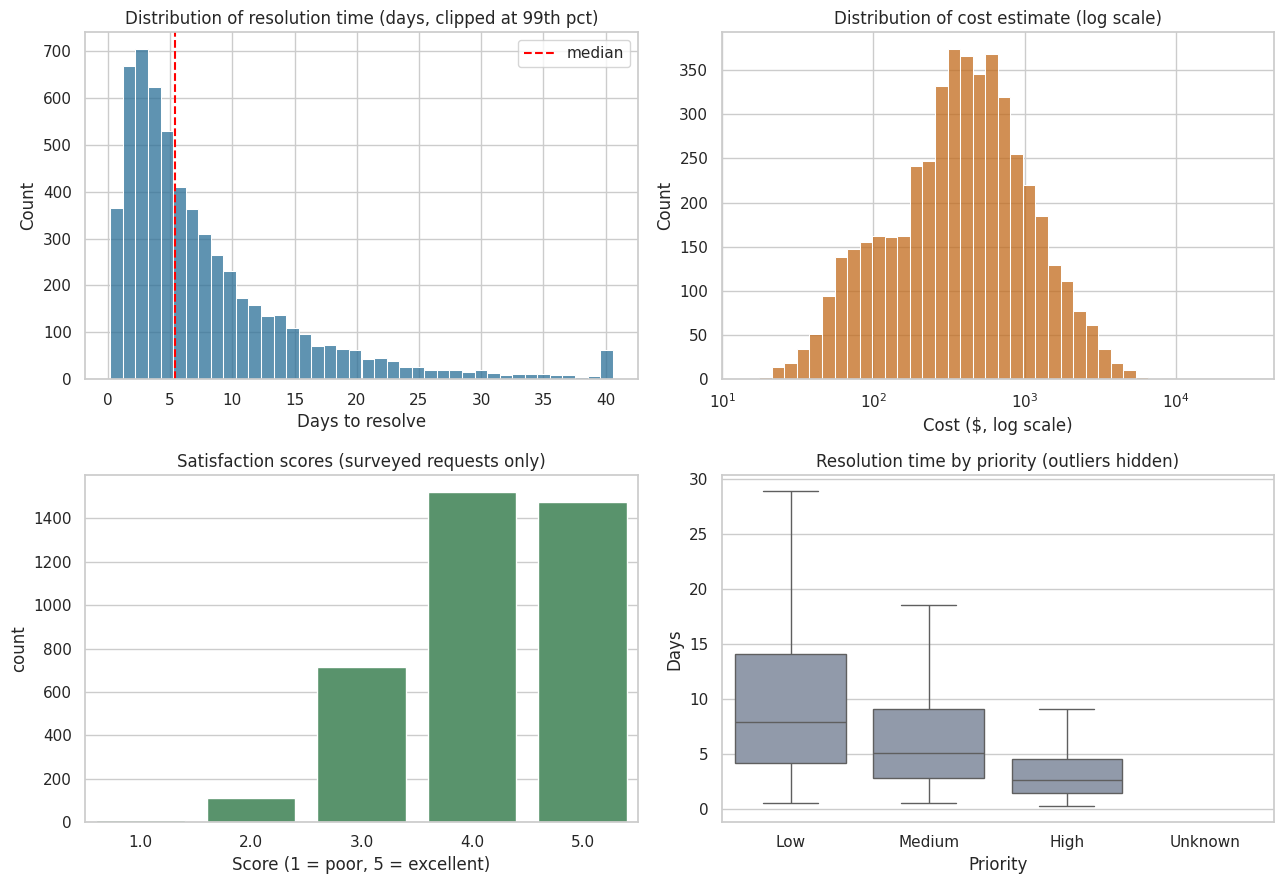

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) Resolution time, clipped at the 99th percentile so the tail doesn't squash the chart
cap = df["resolution_days"].quantile(0.99)
sns.histplot(df["resolution_days"].clip(upper=cap), bins=40, ax=axes[0, 0], color="#2a6f97")
axes[0, 0].axvline(df["resolution_days"].median(), color="red", ls="--", label="median")
axes[0, 0].set(title="Distribution of resolution time (days, clipped at 99th pct)", xlabel="Days to resolve")
axes[0, 0].legend()

# (b) Cost on a log scale because it spans orders of magnitude
sns.histplot(df.loc[df["cost_estimate"] > 0, "cost_estimate"], bins=40, log_scale=True, ax=axes[0, 1], color="#c26a1b")
axes[0, 1].set(title="Distribution of cost estimate (log scale)", xlabel="Cost ($, log scale)")

# (c) Satisfaction is a 1-5 rating -> count plot, not histogram
sns.countplot(x="satisfaction_score", data=df, ax=axes[1, 0], color="#4f9d69")
axes[1, 0].set(title="Satisfaction scores (surveyed requests only)", xlabel="Score (1 = poor, 5 = excellent)")

# (d) Resolution time by priority
sns.boxplot(x="priority", y="resolution_days", data=df[df["priority"] != "Unknown"], ax=axes[1, 1], color="#8d99ae", showfliers=False)
axes[1, 1].set(title="Resolution time by priority (outliers hidden)", xlabel="Priority", ylabel="Days")

plt.tight_layout()
plt.show()

**What the distributions tell us**

- **Resolution time** is right-skewed: the typical (median) request closes in about 5 days, but a long tail takes much longer. This is why we report medians.
- **Cost** spans several orders of magnitude and needs a log scale to be readable; the few extreme values on the right are the outliers we flagged.
- **Satisfaction** is concentrated in the 3–5 range, so we need to be careful that small differences between groups aren't over-interpreted.
- **Priority matters:** higher-priority requests are resolved faster, which is the expected business behavior and a good sanity check on the data.

### 3.3 Missingness (after cleaning)
Not all missing data is a problem. We need to know **why** values are missing. Two kinds appear here:

- **Structural missingness** – blank *by design* (an open request has no closed date).
- **Accidental missingness** – blank because something went wrong (a survey that should exist but doesn't).

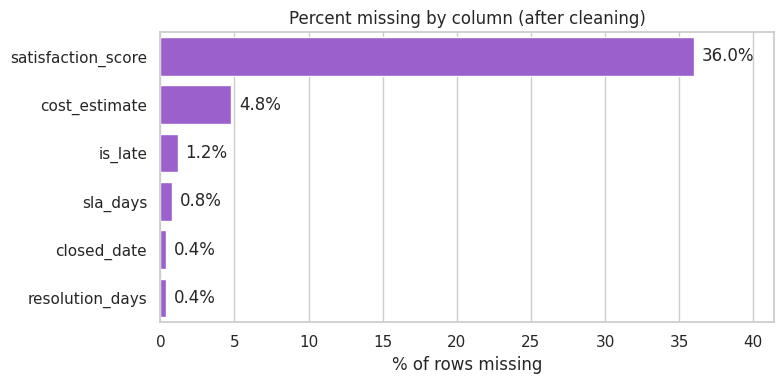

In [13]:
miss = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=miss.values, y=miss.index, ax=ax, color="#9d4edd")
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, f"{v}%", va="center")
ax.set(title="Percent missing by column (after cleaning)", xlabel="% of rows missing", ylabel="")
ax.set_xlim(0, max(miss.values) * 1.15)
plt.tight_layout()
plt.show()

In [14]:
# WHY is satisfaction_score missing? Compare by request status.
pd.crosstab(df["status"], df["satisfaction_score"].notna(), normalize="index").mul(100).round(1).rename(
    columns={True: "% with score", False: "% missing score"}
)

satisfaction_score,% missing score,% with score
status,,
Cancelled,100.00,0.00
Closed,34.70,65.30
Open,100.00,0.00


**Interpretation.** `closed_date`, `resolution_days`, and `is_late` are missing for the few **Open requests (not yet resolved)**, for the rows where we blanked an impossible date, and — for `is_late` — where priority is Unknown. Open is structural, so we do *not* fill those values. `satisfaction_score` is missing for **every Open and Cancelled request** (no survey is sent) and for roughly a third of Closed requests (residents who didn't respond).

**Decision:** we leave these as missing (`NaN`) rather than filling with 0 or the mean, because inventing values would distort averages. In the dashboard, any chart using satisfaction or resolution time will **filter to Closed requests** and say so in its title. This is a **non-response bias** caveat worth stating to the audience: the people who answer surveys may not represent everyone.

---
## 4. Explore categories and investigate the three questions

### 4.1 Category exploration
How are requests spread across the categorical columns? Unbalanced categories affect how we should read every later chart.

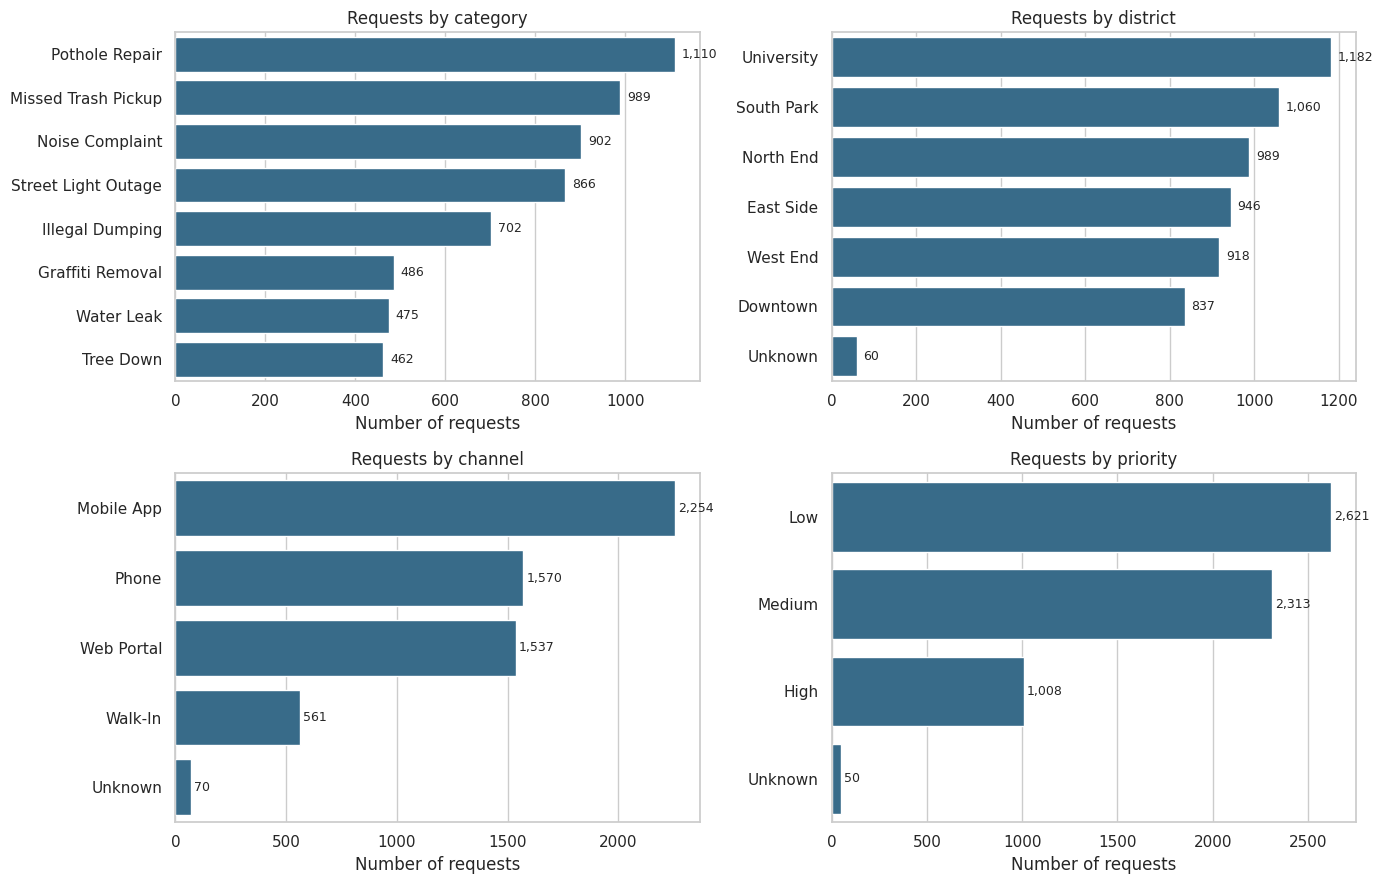

In [15]:
cat_cols = ["category", "district", "channel", "priority"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=ax, color="#2a6f97")
    ax.set(title=f"Requests by {col}", xlabel="Number of requests", ylabel="")
    for p in ax.patches:
        ax.text(p.get_width() + 15, p.get_y() + p.get_height() / 2, f"{int(p.get_width()):,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

### 4.2 `groupby()` and aggregation: one summary table per category
We use **named aggregation** so the output columns have clear names. We restrict speed/satisfaction metrics to **Closed** requests.

In [16]:
closed = df[df["status"] == "Closed"]

category_summary = (
    df.groupby("category")
      .agg(total_requests=("request_id", "count"),
           avg_cost=("cost_estimate", "mean"))
      .join(
          closed.groupby("category").agg(
              median_resolution_days=("resolution_days", "median"),
              pct_late=("is_late", "mean"),
              avg_satisfaction=("satisfaction_score", "mean"),
          )
      )
      .assign(pct_late=lambda d: (d["pct_late"] * 100).round(1))
      .sort_values("median_resolution_days", ascending=False)
)
category_summary

,total_requests,avg_cost,median_resolution_days,pct_late,avg_satisfaction
category,,,,,
Street Light Outage,866,342.82,12.90,75.70,3.89
Pothole Repair,1110,532.32,9.50,59.80,3.97
Tree Down,462,"1,112.26",7.80,43.40,4.08
Illegal Dumping,702,793.32,6.30,30.80,4.13
Graffiti Removal,486,279.39,5.10,22.20,4.13
Water Leak,475,"2,059.79",3.90,13.70,4.14
Missed Trash Pickup,989,98.00,3.40,4.50,4.28
Noise Complaint,902,0.00,2.20,0.70,4.38


### 4.3 Investigating the three proposal questions

#### Q1 — Which categories are slowest, and how much does priority change that?
We build a **pivot table** of median resolution days (category × priority). Sorting rows by overall speed makes the pattern easy to read.

In [17]:
q1 = (
    closed[closed["priority"] != "Unknown"]
    .pivot_table(index="category", columns="priority", values="resolution_days", aggfunc="median", observed=True)
    .round(1)
)
q1 = q1.loc[category_summary.index]          # same order as the summary above
q1

priority,Low,Medium,High
category,,,
Street Light Outage,18.20,11.80,5.70
Pothole Repair,13.80,8.80,4.40
Tree Down,10.80,7.10,3.40
Illegal Dumping,8.80,5.90,2.80
Graffiti Removal,7.70,4.70,2.30
Water Leak,5.60,3.40,1.90
Missed Trash Pickup,4.50,3.00,1.30
Noise Complaint,3.10,1.90,0.90


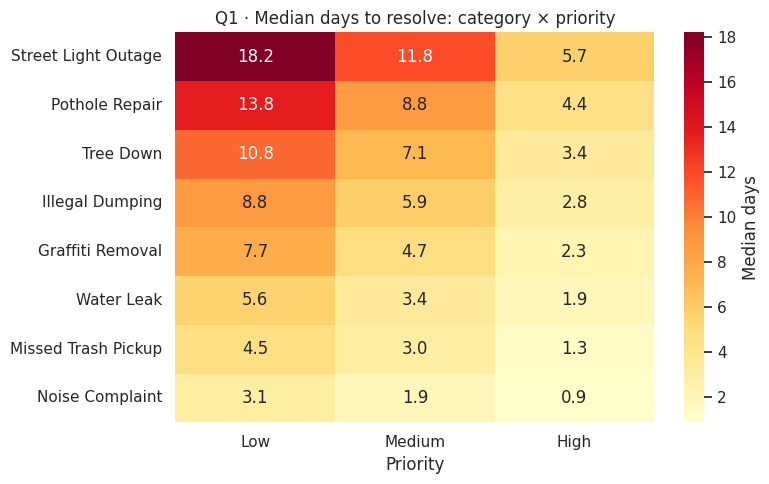

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(q1, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Median days"}, ax=ax)
ax.set(title="Q1 · Median days to resolve: category × priority", xlabel="Priority", ylabel="")
plt.tight_layout()
plt.show()

**Q1 finding.** Infrastructure categories such as **Street Light Outage, Pothole Repair, and Tree Down** are the slowest, while **Noise Complaint and Missed Trash Pickup** resolve fastest. Priority has a large, consistent effect: High-priority requests are resolved roughly 3× faster than Low-priority ones in every category (e.g., Street Light Outage: 18.2 vs. 5.7 days). The *category* sets the baseline; the *priority* scales it. **This is a strong dashboard story** because the audience can filter by priority and watch the ranking shift.

#### Q2 — How has request volume changed over time, and which categories are seasonal?
We group by `year_month` and category, then look at both the overall trend and a month × category heatmap.

In [19]:
monthly = df.groupby("year_month").size().rename("requests").reset_index()
monthly = monthly[monthly["year_month"] < "2025-10-01"]     # drop the partial final month if any
monthly.tail(6)

,year_month,requests
27,2025-04-01,211
28,2025-05-01,222
29,2025-06-01,204
30,2025-07-01,222
31,2025-08-01,198
32,2025-09-01,226


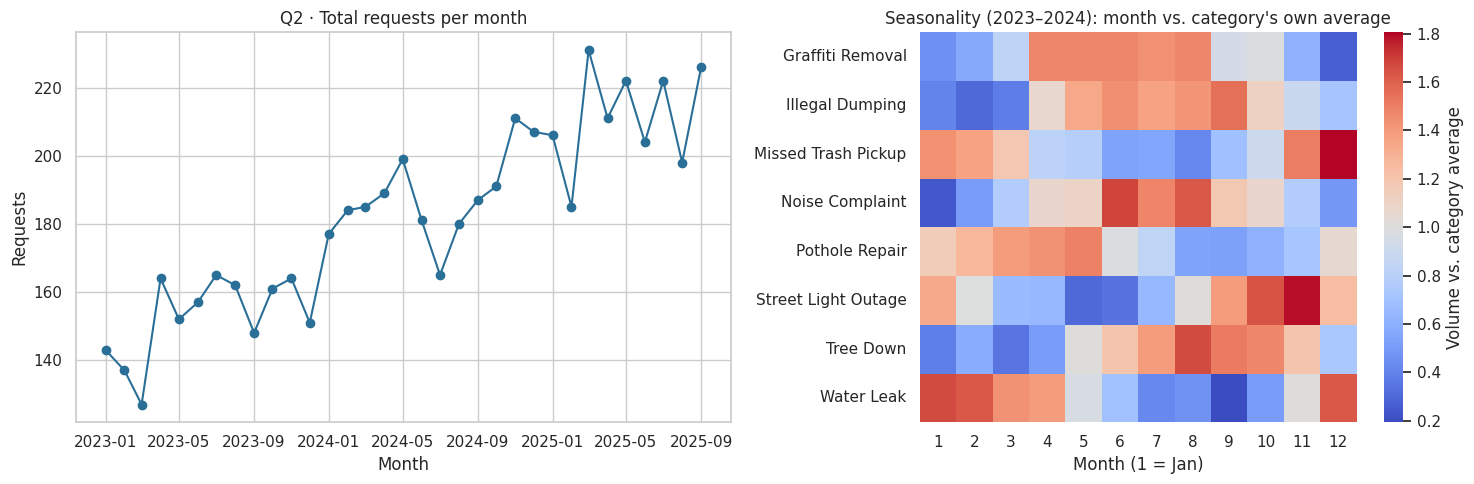

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.2, 1]})

axes[0].plot(monthly["year_month"], monthly["requests"], marker="o", color="#2a6f97")
axes[0].set(title="Q2 · Total requests per month", xlabel="Month", ylabel="Requests")

# Seasonality uses only COMPLETE years (2023-2024). The data stops in Sept 2025, so including 2025
# would count Jan-Sep three times but Oct-Dec only twice and make fall/winter look artificially quiet.
full_years = df[df["year"].isin([2023, 2024])]
season = (full_years.pivot_table(index="category", columns="month", values="request_id", aggfunc="count")
            .pipe(lambda d: d.div(d.mean(axis=1), axis=0)))      # 1.0 = that category's average month
sns.heatmap(season, cmap="coolwarm", center=1, ax=axes[1], cbar_kws={"label": "Volume vs. category average"})
axes[1].set(title="Seasonality (2023–2024): month vs. category's own average", xlabel="Month (1 = Jan)", ylabel="")

plt.tight_layout()
plt.show()

**Q2 finding.** Overall monthly volume trends **upward** over the period (roughly 150 requests/month in 2023 to over 200/month in 2025). The seasonality heatmap shows each category has its own rhythm: **Pothole Repair peaks from winter into spring** (freeze–thaw), **Noise Complaint and Illegal Dumping peak in summer**, **Street Light Outage peaks in November–December** when days are shortest, and **Water Leak and Missed Trash Pickup are strongest in winter** (freezing pipes, holiday pickup disruption). A single "total volume" line would hide all of this — which is why the dashboard needs a **category filter**.

> **Analyst's note — a trap worth knowing:** because the data ends in September 2025, a month-of-year comparison that includes 2025 would be biased (Oct–Dec would have one fewer year of data than Jan–Sep). We limited the seasonality heatmap to the two *complete* years. Always ask whether every group you compare had an equal chance to be observed.

#### Q3 — Do slower resolutions lead to lower satisfaction?
We bucket resolution time into ranges (a calculated column using `pd.cut`) and compare average satisfaction in each bucket. We also check whether the pattern differs by channel.

In [21]:
resp = closed.dropna(subset=["satisfaction_score", "resolution_days"]).copy()
bins = [0, 2, 5, 10, 20, np.inf]
labels = ["≤ 2 days", "2–5 days", "5–10 days", "10–20 days", "20+ days"]
resp["speed_bucket"] = pd.cut(resp["resolution_days"], bins=bins, labels=labels)

q3 = resp.groupby("speed_bucket", observed=True).agg(
    responses=("satisfaction_score", "count"),
    avg_satisfaction=("satisfaction_score", "mean"),
)
q3

,responses,avg_satisfaction
speed_bucket,,
≤ 2 days,578,4.50
2–5 days,1253,4.28
5–10 days,998,4.06
10–20 days,723,3.87
20+ days,269,3.64


In [22]:
print("Correlation (resolution_days vs. satisfaction):",
      round(resp["resolution_days"].corr(resp["satisfaction_score"], method="spearman"), 3), "(Spearman)")
print()
resp.pivot_table(index="channel", columns="speed_bucket", values="satisfaction_score", aggfunc="mean", observed=True).round(2)

Correlation (resolution_days vs. satisfaction): -0.296 (Spearman)



speed_bucket,≤ 2 days,2–5 days,5–10 days,10–20 days,20+ days
channel,,,,,
Mobile App,4.48,4.29,4.09,3.93,3.73
Phone,4.54,4.32,4.09,3.83,3.54
Unknown,4.64,4.20,4.25,3.75,3.00
Walk-In,4.50,4.21,4.05,3.91,3.37
Web Portal,4.48,4.25,3.97,3.82,3.70


**Q3 finding.** Satisfaction **declines steadily as resolution time grows**: residents whose requests close within two days rate the service nearly a full point higher (about 4.5 vs. 3.6) than those who wait 20+ days. The negative Spearman correlation (about −0.3) confirms a real but modest relationship (speed isn't the *only* thing residents care about). The pattern holds across channels, so channel is a secondary filter, not the main story.

> **Caution for your own analysis:** correlation is not causation, and only residents who responded to the survey are included (see non-response note in Section 3.3).

---
## 5. Visualizations with filters (the dashboard charts)

The final product is an interactive Streamlit dashboard where the viewer picks filters (year, district, category, ...). To prepare for that, every chart below is built from two pieces:

1. **`apply_filters()`** – one reusable function that narrows the DataFrame. In Streamlit, the arguments will come from sidebar widgets (`st.sidebar.multiselect`, `st.sidebar.slider`, ...).
2. **A `plot_...()` function** – takes the filter values and draws the chart.

Writing charts as *filter → aggregate → plot* functions makes the notebook almost a copy-paste blueprint for `app.py`.

In [23]:
def apply_filters(data, years=None, districts=None, categories=None,
                  priorities=None, channels=None, statuses=None):
    """Return the rows that match every filter. A filter left as None means 'no restriction'."""
    out = data
    if years is not None:      out = out[out["year"].isin(years)]
    if districts is not None:  out = out[out["district"].isin(districts)]
    if categories is not None: out = out[out["category"].isin(categories)]
    if priorities is not None: out = out[out["priority"].isin(priorities)]
    if channels is not None:   out = out[out["channel"].isin(channels)]
    if statuses is not None:   out = out[out["status"].isin(statuses)]
    return out

# Quick test of the helper
test = apply_filters(df, years=[2025], statuses=["Closed"])
print(f"{len(test):,} rows match year = 2025 and status = Closed (out of {len(df):,})")

1,858 rows match year = 2025 and status = Closed (out of 5,992)


### Chart 1 — Median resolution time by category *(answers Q1)*
**Filters used:** `years`, `priorities`, and (always) `statuses = Closed`.

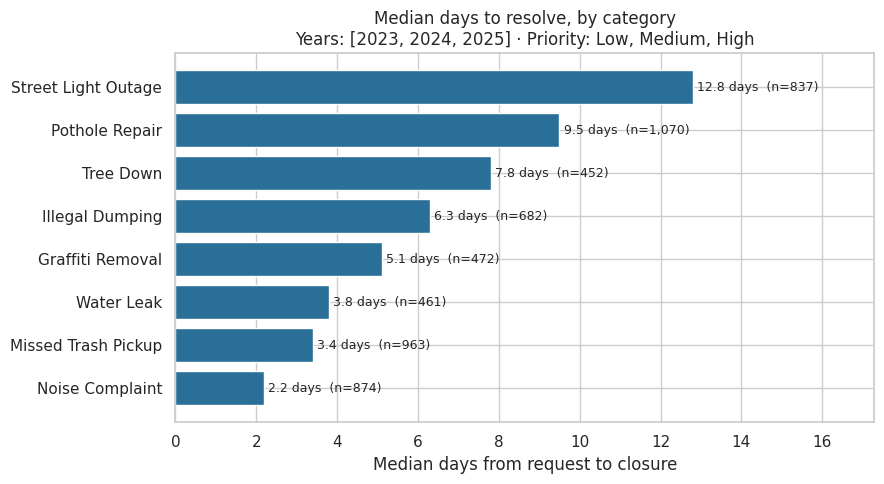

In [24]:
def plot_resolution_by_category(years, priorities):
    data = apply_filters(df, years=years, priorities=priorities, statuses=["Closed"])
    summary = (data.groupby("category")["resolution_days"]
                   .agg(median="median", n="count")
                   .sort_values("median"))
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(summary.index, summary["median"], color="#2a6f97")
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                f"{row['median']:.1f} days  (n={int(row['n']):,})", va="center", fontsize=9)
    ax.set(title=f"Median days to resolve, by category\nYears: {sorted(years)} · Priority: {', '.join(map(str, priorities))}",
           xlabel="Median days from request to closure", ylabel="")
    ax.set_xlim(0, summary["median"].max() * 1.35)
    plt.tight_layout()
    plt.show()
    return summary

# Filter set A: all years, all known priorities
_ = plot_resolution_by_category(years=[2023, 2024, 2025], priorities=["Low", "Medium", "High"])

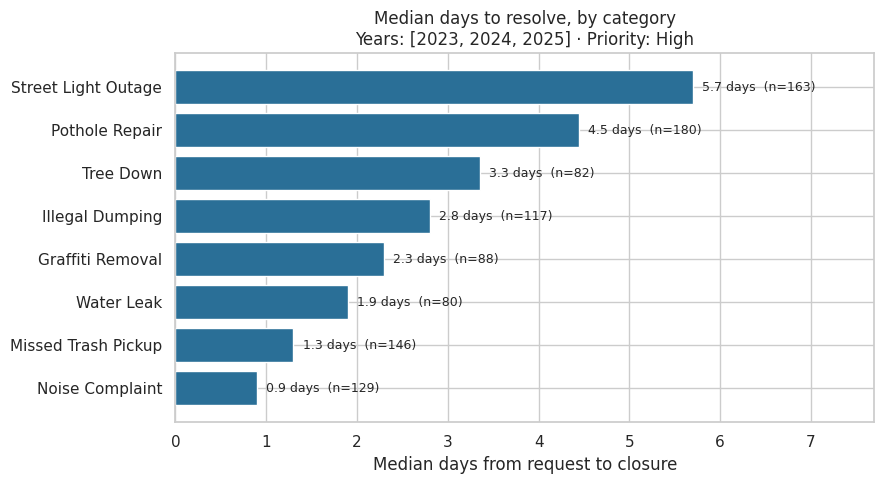

In [25]:
# Filter set B: same function, High priority only -> the ranking and the scale change
_ = plot_resolution_by_category(years=[2023, 2024, 2025], priorities=["High"])

**What it shows.** Each bar is the *median* number of days between a request being created and closed, for one category. Switching the priority filter from all priorities to High only shrinks every bar to roughly a third of its size, while the ranking of categories stays nearly the same — the category sets the baseline and priority scales it.

**Why it matters to the audience.** City managers can see immediately **which request types need more crews or faster workflows** and check whether High-priority requests really get fast treatment. Showing `n` on each bar tells the viewer how much data backs each bar, which prevents over-reading small groups.

In [26]:
# Does the Year filter change the story? Compare median resolution by year (Closed requests)
closed.groupby("year")["resolution_days"].agg(median="median", requests="count")

,median,requests
year,,
2023,5.90,1788
2024,6.00,2218
2025,4.60,1853


**Year filter insight.** Resolution times were flat in 2023–2024 (~6 days median) and **dropped to ~4.6 days in 2025**. A viewer who selects only 2025 sees noticeably shorter bars, which is exactly why a Year filter belongs on Chart 1.

### Chart 2 — Monthly request volume by category *(answers Q2)*
**Filters used:** `categories`, `districts`.

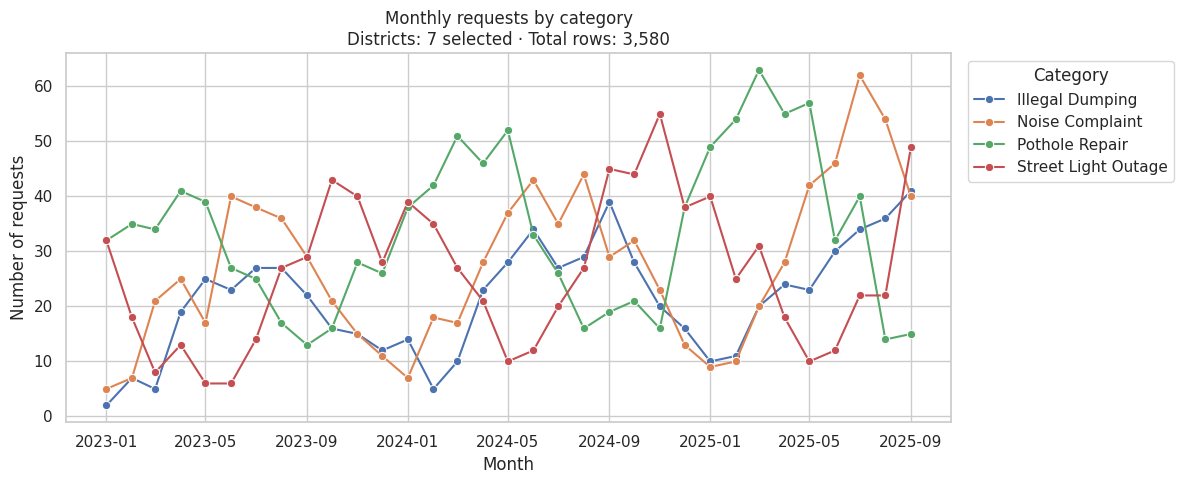

In [27]:
def plot_monthly_volume(categories, districts):
    data = apply_filters(df, categories=categories, districts=districts)
    data = data[data["year_month"] < "2025-10-01"]
    trend = (data.groupby(["year_month", "category"]).size()
                 .rename("requests").reset_index())
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.lineplot(data=trend, x="year_month", y="requests", hue="category", marker="o", ax=ax)
    ax.set(title=f"Monthly requests by category\nDistricts: {len(districts)} selected · Total rows: {len(data):,}",
           xlabel="Month", ylabel="Number of requests")
    ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    return trend

all_districts = sorted(df["district"].unique())
_ = plot_monthly_volume(categories=["Pothole Repair", "Noise Complaint", "Street Light Outage", "Illegal Dumping"],
                        districts=all_districts)

**What it shows.** One line per selected category, tracing how many requests were submitted each month from January 2023 to September 2025.

**Why it matters to the audience.** Operations planners can **staff ahead of the seasons**: potholes in spring, noise and dumping in summer, street lights in late fall. Because the lines can be filtered by district, a district council can check whether *their* area follows the citywide pattern. The upward drift also shows demand is growing year over year.

### Chart 3 — Satisfaction vs. resolution speed *(answers Q3)*
**Filters used:** `channels`, `districts`, and (always) `statuses = Closed`.

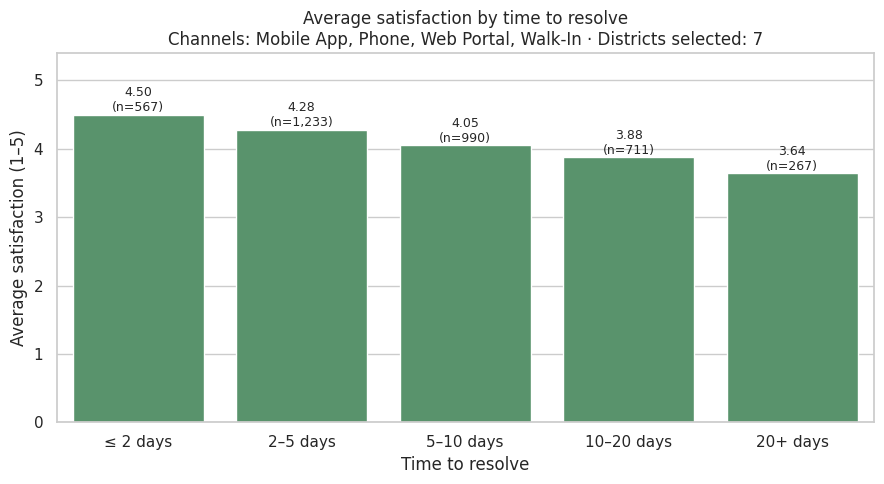

In [28]:
def plot_satisfaction_vs_speed(channels, districts):
    data = apply_filters(df, channels=channels, districts=districts, statuses=["Closed"])
    data = data.dropna(subset=["satisfaction_score", "resolution_days"]).copy()
    data["speed_bucket"] = pd.cut(data["resolution_days"], bins=bins, labels=labels)
    summary = (data.groupby("speed_bucket", observed=True)["satisfaction_score"]
                   .agg(avg="mean", n="count").reset_index())
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(data=summary, x="speed_bucket", y="avg", color="#4f9d69", ax=ax)
    for i, row in summary.iterrows():
        ax.text(i, row["avg"] + 0.05, f"{row['avg']:.2f}\n(n={int(row['n']):,})", ha="center", fontsize=9)
    ax.set(title=f"Average satisfaction by time to resolve\nChannels: {', '.join(channels)} · Districts selected: {len(districts)}",
           xlabel="Time to resolve", ylabel="Average satisfaction (1–5)", ylim=(0, 5.4))
    plt.tight_layout()
    plt.show()
    return summary

all_channels = ["Mobile App", "Phone", "Web Portal", "Walk-In"]
_ = plot_satisfaction_vs_speed(channels=all_channels, districts=all_districts)

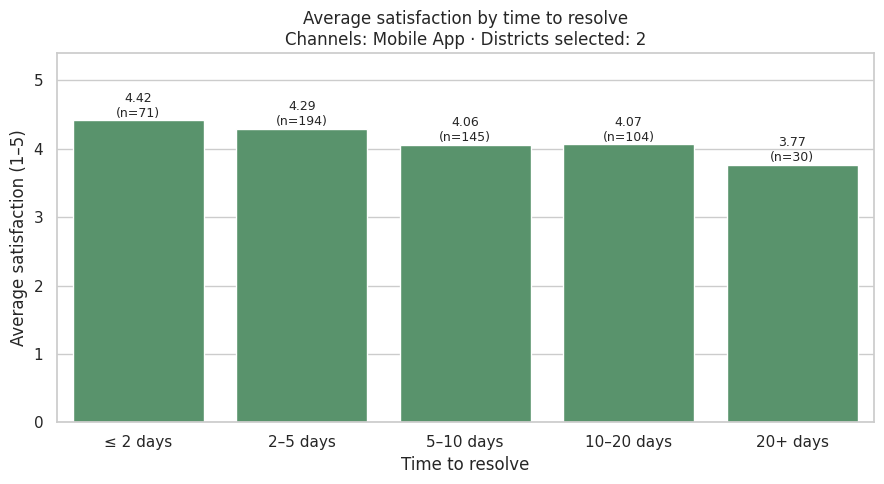

In [29]:
# Same chart, filtered to one channel and the two districts with the most requests
top_districts = df["district"].value_counts().head(2).index.tolist()
_ = plot_satisfaction_vs_speed(channels=["Mobile App"], districts=top_districts)

**What it shows.** Average 1–5 satisfaction score for residents grouped by how long their request took to close. Bars drop as waiting time increases.

**Why it matters to the audience.** It turns an abstract goal ("improve service") into a **measurable target**: shortening the longest waits is linked to happier residents. The sample size on each bar signals when a filtered view has too little data to trust (the second filter set has noticeably smaller `n`).

---
## 6. Which charts go in the dashboard?

All three charts above are strong enough for the final dashboard: each answers one proposal question, each is meaningfully changed by its filters, and together they tell a coherent story (**how fast → when → how residents feel**).

| Rank | Chart | Proposal question | Dashboard widget(s) | Streamlit element |
|---|---|---|---|---|
| 1 | Median resolution time by category | Q1 | Year multiselect, Priority multiselect | `st.bar_chart` / `st.pyplot` |
| 2 | Monthly volume by category | Q2 | Category multiselect, District multiselect | `st.line_chart` / `st.pyplot` |
| 3 | Satisfaction vs. resolution speed | Q3 | Channel multiselect, District multiselect | `st.bar_chart` / `st.pyplot` |

**Why these three beat the other charts in this notebook:** the distribution histograms, missingness chart, and category counts are essential for *understanding and cleaning* the data, but they describe the dataset, not the audience's questions. The Q1 heatmap is an excellent supporting visual, but the bar chart communicates the same ranking faster with an interactive filter.

**Suggested KPI cards above the charts:** total requests, median resolution days, % late, average satisfaction.

---
## 7. Save the dashboard dataset

The dashboard should load a **small, clean, purpose-built CSV**, not the raw file. We:

1. Keep only the **columns** the three charts and filters need (drop columns the dashboard never touches).
2. Keep the **rows** the dashboard needs. We keep Open and Cancelled requests because Chart 2 counts *all* requests.
3. Remove helper columns that were only used for cleaning.
4. Check the file size (**target: under 25 MB**) and confirm the CSV reloads correctly.

In [30]:
dashboard_cols = [
    "request_id", "created_date", "closed_date", "year", "month", "year_month",
    "category", "district", "channel", "priority", "status",
    "resolution_days", "sla_days", "is_late", "satisfaction_score",
    "cost_estimate", "cost_is_outlier",
]

dash = df[dashboard_cols].copy()
dash["priority"] = dash["priority"].astype(str)                 # categoricals -> plain text for CSV
dash["resolution_days"] = dash["resolution_days"].round(2)
dash["cost_estimate"] = dash["cost_estimate"].round(2)
dash["is_late"] = dash["is_late"].astype("Int64")               # 1 / 0 / blank (nullable integer)
dash["cost_is_outlier"] = dash["cost_is_outlier"].astype(bool)
dash = dash.sort_values("created_date").reset_index(drop=True)

dash.to_csv(DASHBOARD_FILE, index=False)

import os
size_mb = os.path.getsize(DASHBOARD_FILE) / 1_048_576
print(f"Saved {DASHBOARD_FILE}: {dash.shape[0]:,} rows x {dash.shape[1]} columns, {size_mb:.2f} MB")
print("Under 25 MB target:", size_mb < 25)

Saved dashboard_data.csv: 5,992 rows x 17 columns, 0.81 MB
Under 25 MB target: True


### 7.1 Validate the saved file
Reload the CSV the way the Streamlit app will (`parse_dates` for date columns) and confirm types, missing values, and a final filter test work. **If your dashboard breaks later, this is the first place to look.**

In [31]:
check = pd.read_csv(DASHBOARD_FILE, parse_dates=["created_date", "closed_date", "year_month"])
print(check.dtypes.to_string())
print()
print("Missing values per column (should only be in the 'by design' columns):")
print(check.isna().sum()[check.isna().sum() > 0].to_string())
print()
print("Round-trip check, same filters as Chart 1 on the reloaded file:")
test = check[(check["year"].isin([2024, 2025])) & (check["status"] == "Closed") & (check["priority"] == "High")]
print(f"{len(test):,} rows; median resolution = {test['resolution_days'].median():.2f} days")

request_id                       str
created_date          datetime64[us]
closed_date           datetime64[us]
year                           int64
month                          int64
year_month            datetime64[us]
category                         str
district                         str
channel                          str
priority                         str
status                           str
resolution_days              float64
sla_days                     float64
is_late                      float64
satisfaction_score           float64
cost_estimate                float64
cost_is_outlier                 bool

Missing values per column (should only be in the 'by design' columns):
closed_date             21
resolution_days         21
sla_days                50
is_late                 71
satisfaction_score    2159
cost_estimate          289

Round-trip check, same filters as Chart 1 on the reloaded file:
707 rows; median resolution = 2.55 days


---
## 8. Dashboard hand-off specification (for the AI-assisted Streamlit build)

> **Student note:** this notebook will be given to an AI tool to help generate `app.py`. A clear spec at the end dramatically improves the result. Write one for your own project in this same format. Include the *exact* file name, column names, and filter logic so the AI doesn't have to guess.

### Files
- Data file in the GitHub repo: **`dashboard_data.csv`** (same folder as `app.py`)
- Python libraries: `streamlit`, `pandas`, `numpy`, `matplotlib`, `seaborn`

### `requirements.txt`
```
streamlit
pandas
numpy
matplotlib
seaborn
```

### Data loading
```python
@st.cache_data
def load_data():
    return pd.read_csv("dashboard_data.csv", parse_dates=["created_date", "closed_date", "year_month"])
```

### Column reference
| Column | Type | Notes |
|---|---|---|
| `request_id` | text | unique ID |
| `created_date`, `closed_date` | datetime | `closed_date` blank for Open |
| `year`, `month` | int | from `created_date` |
| `year_month` | datetime | first day of the month; use for time axes |
| `category` | text | 8 values |
| `district` | text | 6 official names + `Unknown` |
| `channel` | text | Mobile App, Phone, Web Portal, Walk-In, `Unknown` |
| `priority` | text | Low, Medium, High, `Unknown` (order: Low → Medium → High) |
| `status` | text | Open, Closed, Cancelled |
| `resolution_days` | float | blank unless Closed; **use median, not mean** |
| `sla_days`, `is_late` | int | `is_late` is 1/0; blank if not closed |
| `satisfaction_score` | float | 1–5; survey responses only |
| `cost_estimate`, `cost_is_outlier` | float / bool | exclude outliers from cost averages |

### Sidebar filters
| Widget | Column | Default |
|---|---|---|
| Multiselect "Year" | `year` | all |
| Multiselect "District" | `district` | all |
| Multiselect "Category" | `category` | all |
| Multiselect "Priority" | `priority` | Low, Medium, High |
| Multiselect "Channel" | `channel` | all |

### Layout
1. **Title and one-sentence purpose.**
2. **KPI row** (respects all filters): total requests · median resolution days (Closed only) · % late (Closed only) · average satisfaction (surveyed only).
3. **Chart 1** – horizontal bar, median `resolution_days` by `category`, Closed only, use Year + Priority filters; label bars with `n`.
4. **Chart 2** – line chart, requests per `year_month` by `category`, use Category + District filters.
5. **Chart 3** – bar chart, average `satisfaction_score` by resolution-time bucket (`≤2`, `2–5`, `5–10`, `10–20`, `20+` days), Closed + surveyed only, use Channel + District filters; label bars with `n`.
6. **Interpretation text** under each chart (what it shows, why it matters), taken from Section 5 of this notebook.
7. **Footer:** data source, last updated date, and the non-response caveat for satisfaction.

### Behavior requirements
- Every chart must have a title, axis labels, and units.
- If filters return **zero rows**, show `st.warning("No data for the selected filters")` instead of crashing.
- Reuse the `apply_filters()` logic from Section 5 rather than re-inventing it.